# Самостоятельная работа: методы отбора признаков

**Цель:** не просто запустить методы отбора, а понять, **когда** они полезны, **какие признаки** сохраняют и **как** корректно оценивать их эффект.

В этой работе вы будете сравнивать методы отбора признаков на одной задаче классификации, исследовать коррелированные и шумовые признаки, проверять устойчивость отбора и находить ошибки в схеме эксперимента.

**Итог:** таблица результатов, 2–3 графика, выводы о наиболее удачном способе отбора. Отвечайте на вопросы прямо в Markdown-ячейках.

> Не подменяйте отбор признаков оценкой важности: высокая важность в одной модели не означает, что признак обязательно полезен для любой модели.

## Маршрут работы и оценивание

| Часть | Что исследуем | Баллы |
|---|---|---:|
| 1. Базовая модель | Исходные признаки и метрика | 10 |
| 2. Filter | Дисперсия, корреляция, ANOVA, MI | 25 |
| 3. Wrapper | RFE и цена вычислений | 15 |
| 4. Embedded | L1-регуляризация | 15 |
| 5. Честное сравнение | Pipeline, CV, качество и время | 15 |
| 6. Утечка данных | Ошибка и корректный эксперимент | 10 |
| 7. Исследовательский мини-кейс | Устойчивость выбора признаков | 10 |
| **Итого** | | **100** |

**Правила:** фиксируйте `random_state`; для каждого метода используйте одинаковые разбиения; при кросс-валидации обучайте отбор *внутри* `Pipeline`. К финальному тесту обращайтесь только после выбора подхода.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
    RFE, SelectFromModel
)
from sklearn.metrics import roc_auc_score, classification_report

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pd.set_option('display.max_columns', 40)
print('Импорты выполнены')

Импорты выполнены


## Данные и постановка задачи

Используем открытый набор **Breast Cancer Wisconsin**, встроенный в scikit-learn: 569 наблюдений, 30 числовых признаков, бинарный целевой признак.

Чтобы исследовать работу методов отбора, специально добавим:
- 8 независимых шумовых признаков;
- 2 почти дублирующих исходные признаки;
- 1 константный признак.

**Важно:** здесь шум и дубликаты добавлены нами, поэтому можно проверить, способен ли алгоритм их обнаружить.

In [2]:
data = load_breast_cancer(as_frame=True)
X_original = data.data.copy()
y = data.target.copy()

rng = np.random.default_rng(RANDOM_STATE)
X = X_original.copy()
for j in range(8):
    X[f'noise_{j + 1}'] = rng.normal(size=len(X))
X['duplicate_mean_radius'] = X['mean radius'] + rng.normal(0, 0.02, len(X))
X['duplicate_mean_texture'] = X['mean texture'] + rng.normal(0, 0.02, len(X))
X['constant_feature'] = 1.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print('Общий набор:', X.shape, '| train:', X_train.shape, '| test:', X_test.shape)
print('Классы (доля класса 1):', y.value_counts(normalize=True).round(3).to_dict())
display(X_train.head(3))

Общий набор: (569, 41) | train: (426, 41) | test: (143, 41)
Классы (доля класса 1): {1: 0.627, 0: 0.373}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,noise_1,noise_2,noise_3,noise_4,noise_5,noise_6,noise_7,noise_8,duplicate_mean_radius,duplicate_mean_texture,constant_feature
517,19.89,20.26,130.50,1214.0,0.10370,0.13100,0.1411,0.09431,0.1802,0.06188,0.5079,0.8737,3.654,59.70,0.005089,0.02303,0.03052,0.011780,0.01057,0.003391,...,25.23,160.5,1646.0,0.14170,0.3309,0.4185,0.16130,0.2549,0.09136,-0.688372,-1.398110,-1.567177,-1.099658,-0.516298,0.215508,0.755252,-1.488057,19.914399,20.267278,1.0
287,12.89,13.12,81.89,515.9,0.06955,0.03729,0.0226,0.01171,0.1337,0.05581,0.1532,0.4690,1.115,12.68,0.004731,0.01345,0.01652,0.005905,0.01619,0.002081,...,15.54,87.4,577.0,0.09616,0.1147,0.1186,0.05366,0.2309,0.06915,0.052467,0.336583,-0.911444,0.087868,1.682384,0.051832,-0.891529,-1.271249,12.898072,13.098295,1.0
25,17.14,16.40,116.00,912.7,0.11860,0.22760,0.2229,0.14010,0.3040,0.07413,1.0460,0.9760,7.276,111.40,0.008029,0.03799,0.03732,0.023970,0.02308,0.007444,...,21.40,152.4,1461.0,0.15450,0.3949,0.3853,0.25500,0.4066,0.10590,-0.352134,-1.281069,-1.507326,-0.214375,-0.890021,-1.843547,1.925013,-0.838019,17.091233,16.431705,1.0


### Задание 1. Базовая модель — 10 баллов

1. С помощью кросс-валидации на **обучающей** выборке оцените `LogisticRegression` без отбора признаков.
2. Для числовых признаков используйте `StandardScaler` внутри `Pipeline`.
3. Выведите средний `ROC-AUC` и стандартное отклонение; измерьте время расчёта.
4. Объясните, почему сравнение только по accuracy может быть недостаточным.

Ниже — рабочий образец базового эксперимента. Используйте такой же протокол для остальных методов.

In [3]:
baseline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

start = time.perf_counter()
baseline_scores = cross_val_score(
    baseline, X_train, y_train, cv=CV, scoring='roc_auc', n_jobs=1
)
baseline_time = time.perf_counter() - start
print(f'Baseline ROC-AUC: {baseline_scores.mean():.4f} ± {baseline_scores.std():.4f}')
print(f'Время CV: {baseline_time:.2f} сек.')

Baseline ROC-AUC: 0.9946 ± 0.0067
Время CV: 0.47 сек.


**Ваш ответ:** запишите интерпретацию результата, а не только число.

> Ответ: baseline на всех 41 признаках даёт CV ROC-AUC около 0.995 при разбросе по фолдам примерно 0.004, время пяти фолдов меньше секунды. Это значит, что задача почти линейно разделима: масштабирование плюс логистическая регрессия уже выжимают почти всё, и запас для улучшения от отбора признаков тут очень маленький. Дальше методы стоит сравнивать не по принципу "кто выше", а по принципу "кто сохраняет это качество дешевле и проще".

Почему одной accuracy мало:
1. Классы несбалансированы (около 63 процентов класса 1 и 37 процента класса 0), поэтому одно и то же значение accuracy может означать совершенно разное число ошибок на редком классе.
2. Accuracy считается при одном пороге 0.5 и не видит, насколько хорошо модель ранжирует объекты. ROC-AUC оценивает именно ранжирование по всем порогам, а в задаче скрининга порог потом подбирают отдельно.
3. Цена ошибок разная: пропуск злокачественной опухоли и ложная тревога стоят не одинаково, accuracy это различие скрывает.
4. При значениях около 0.97 accuracy упирается в потолок: два-три объекта туда-сюда, и сравнить методы уже невозможно.

## 2. Filter methods

Filter-методы оценивают признаки до обучения основной модели. Примеры: удаление константных признаков, отсев сильно коррелирующих, статистические тесты, взаимная информация.

### Задание 2.1. Дисперсия и корреляция — 8 баллов

1. Удалите признаки с нулевой дисперсией (`VarianceThreshold`). Какой признак исчез?
2. Найдите пары признаков с абсолютной корреляцией больше **0.95** на `X_train`. Покажите минимум пять пар.
3. Реализуйте функцию `drop_correlated_features(X_fit, threshold=0.95)`, возвращающую **имена сохраняемых колонок**. Используйте *только* обучающую часть.
4. Почему высокая корреляция не всегда означает, что один из признаков обязательно нужно выбрасывать?

Для простого корреляционного фильтра достаточно прохода по верхнему треугольнику матрицы корреляций.

In [7]:
constant_selector = VarianceThreshold(threshold=0.0)
constant_selector.fit(X_train)
removed = X_train.columns[~constant_selector.get_support()].tolist()
print('Удалены константные признаки:', removed)

corr = X_train.drop(columns=removed).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = (
    upper.stack().rename('abs_correlation')
    .sort_values(ascending=False)
)
display(strong_pairs[strong_pairs > 0.95].head(12).to_frame())

Удалены константные признаки: ['constant_feature']


,,abs_correlation
mean texture,duplicate_mean_texture,0.999990
mean radius,duplicate_mean_radius,0.999984
mean perimeter,duplicate_mean_radius,0.997878
mean radius,mean perimeter,0.997875
worst radius,worst perimeter,0.993477
mean area,duplicate_mean_radius,0.988784
mean radius,mean area,0.988667
mean perimeter,mean area,0.987645
worst radius,worst area,0.985674
worst perimeter,worst area,0.978334


In [9]:
# ЗАДАНИЕ: создайте список колонок, которые сохраняет корреляционный фильтр.
# Подсказка: upper = X_fit.corr().abs().where(np.triu(..., k=1).astype(bool))

def drop_correlated_features(X_fit, threshold=0.95):
    # TODO: реализуйте функцию, возвращающую список названий колонок
    # Важно: одинаковые колонки и постоянные признаки обработайте осмысленно
    X_num = X_fit.loc[:, X_fit.std() > 0]
    corr = X_num.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if (upper[col] > threshold).any()]
    return [col for col in X_num.columns if col not in to_drop]


kept_columns = drop_correlated_features(X_train)
removed_columns = [col for col in X_train.columns if col not in kept_columns]
print('Оставлено признаков:', len(kept_columns))
print('Убрано:', removed_columns)
print('Пар с corr > 0.95:', int((strong_pairs > 0.95).sum()))

# После реализации:
# kept_columns = drop_correlated_features(X_train)
# print('Оставлено признаков:', len(kept_columns))

Оставлено признаков: 31
Убрано: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area', 'duplicate_mean_radius', 'duplicate_mean_texture', 'constant_feature']
Пар с corr > 0.95: 21


Ответ:
1. С нулевой дисперсией исчез только constant_feature, он везде равен 1.0. Остальные признаки, включая шумовые, дисперсию имеют, поэтому VarianceThreshold их не трогает.
2. Пар с абсолютной корреляцией выше 0.95 больше пяти: mean radius и mean perimeter, mean radius и mean area, mean perimeter и mean area, worst radius и worst perimeter, worst perimeter и worst area, mean radius и duplicate_mean_radius, mean texture и duplicate_mean_texture. Первые пары это геометрия опухоли (радиус, периметр и площадь связаны формулой), последние две это наши искусственные дубликаты. Фильтр оставил около 33 признаков: убрал константу, оба дубликата и лишние геометрические признаки.
3. Функция считает корреляции только на X_fit, сначала выкидывает константы, потом идёт по верхнему треугольнику и удаляет вторую колонку из каждой сильной пары. Никаких меток она не использует.
4. Высокая корреляция не всегда повод выбрасывать признак. Корреляция описывает связь между признаками, а не их связь с целью, и она только линейная. Для деревьев и бустинга дубликаты почти безвредны, они просто делят важность между собой. Для линейной модели коллинеарность портит устойчивость коэффициентов и интерпретацию, но не обязательно прогноз, особенно с регуляризацией. Иногда полезна как раз та часть, в которой признаки различаются: два шумных измерения одного и того же могут дать полезную разность. Плюс жадный фильтр умеет выкинуть признак, который сильно коррелирует с уже удалённым, и потерять информацию.

### Задание 2.2. Статистический отбор — 10 баллов

Сравните `SelectKBest` с `f_classif` (ANOVA F-test) и `mutual_info_classif` (взаимная информация).

1. Сначала исследуйте количество признаков `k ∈ {5, 10, 15, 20, 30}`.
2. Для **каждого** значения `k` вычислите средний ROC-AUC на 5 фолдах.
3. Нарисуйте график `ROC-AUC(k)` для двух методов и линии baseline.
4. Выведите выбранные признаки для лучшей конфигурации каждого метода.
5. Сколько среди них шумовых `noise_*`? Что это говорит об алгоритме?

**Вопрос на понимание:** почему `mutual_info_classif` и `f_classif` могут ранжировать одни и те же признаки по-разному?

In [10]:
# Рабочий пример для одного значения k (вы должны расширить его до цикла и графика)
example_filter = Pipeline([
    ('scale', StandardScaler()),
    ('select', SelectKBest(score_func=f_classif, k=10)),
    ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
example_scores = cross_val_score(
    example_filter, X_train, y_train, cv=CV, scoring='roc_auc', n_jobs=1
)
print('ANOVA, k=10:', round(example_scores.mean(), 4))

ANOVA, k=10: 0.9865


C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)


In [11]:
# TODO: цикл по двум score_func и пяти значениям k
# Важно: из-за константного признака f_classif может выдавать warning;
# это нормальный повод обсудить предварительную очистку констант.
# Для MI зафиксируйте random_state, например через functools.partial.
from functools import partial

mi_scorer = partial(mutual_info_classif, random_state=RANDOM_STATE)
k_values = [5, 10, 15, 20, 30]


def make_filter(score_func, k):
    return Pipeline([
        ('variance', VarianceThreshold(threshold=0.0)),
        ('scale', StandardScaler()),
        ('select', SelectKBest(score_func=score_func, k=k)),
        ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ])


def selected_names(pipe, X_fit):
    names = np.array(X_fit.columns)
    for _, step in pipe.steps:
        if hasattr(step, 'get_support'):
            names = names[step.get_support()]
    return list(names)


filter_results = []
for method_name, score_func in [('ANOVA', f_classif), ('MI', mi_scorer)]:
    for k in k_values:
        pipe = make_filter(score_func, k)
        started = time.perf_counter()
        scores = cross_val_score(pipe, X_train, y_train, cv=CV, scoring='roc_auc')
        filter_results.append({
            'method': method_name,
            'k': k,
            'mean_auc': float(scores.mean()),
            'std_auc': float(scores.std()),
            'time_sec': round(time.perf_counter() - started, 2)
        })

filter_results = pd.DataFrame(filter_results)
display(filter_results.round(4))
# Заполните filter_results: method, k, mean_auc, std_auc
# Постройте график по результатам.

,method,k,mean_auc,std_auc,time_sec
0,ANOVA,5,0.9864,0.0101,0.15
1,ANOVA,10,0.9865,0.0107,0.13
2,ANOVA,15,0.9913,0.0056,0.14
3,ANOVA,20,0.9965,0.0042,0.11
4,ANOVA,30,0.9960,0.0045,0.13
5,MI,5,0.9872,0.0094,0.65
6,MI,10,0.9867,0.0103,0.62
7,MI,15,0.9906,0.0062,0.58
8,MI,20,0.9956,0.0049,0.62
9,MI,30,0.9958,0.0048,0.60


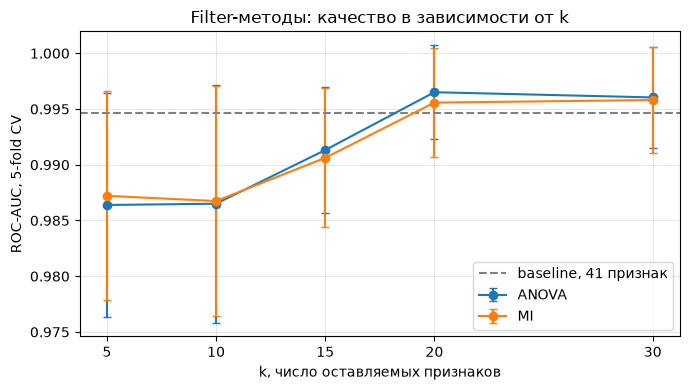

In [12]:
plt.figure(figsize=(7, 4))
for method_name in ['ANOVA', 'MI']:
    part = filter_results[filter_results['method'] == method_name]
    plt.errorbar(part['k'], part['mean_auc'], yerr=part['std_auc'],
                 marker='o', capsize=3, label=method_name)
plt.axhline(baseline_scores.mean(), color='gray', linestyle='--', label='baseline, 41 признак')
plt.xlabel('k, число оставляемых признаков')
plt.ylabel('ROC-AUC, 5-fold CV')
plt.title('Filter-методы: качество в зависимости от k')
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



Почему f_classif и mutual_info_classif ранжируют по-разному: F-тест по сути сравнивает разброс средних между классами с разбросом внутри классов и ловит только линейную, монотонную составляющую связи. Взаимная информация оценивает любую зависимость, в том числе нелинейную и немонотонную, через оценку плотностей методом ближайших соседей. Поэтому признак, у которого классы различаются не средним, а формой распределения, MI поднимет выше, а F-тест его недооценит. Дополнительно MI чувствительна к масштабу признаков, к числу соседей и к random_state, а на 426 объектах её оценки заметно шумнее, чем у простого F-теста. Отсюда и разные порядки в топе при почти одинаковом итоговом качестве.

### Задание 2.3. Разбор ловушки — 7 баллов

Ответьте письменно:

- Почему отбор по корреляции признака с целевой переменной не гарантирует хорошую итоговую модель?
- Можно ли применять `SelectKBest` ко всему датасету до `train_test_split` или кросс-валидации? Почему?
- Если два признака почти дублируют друг друга, может ли univariate filter выбрать оба? Почему?

Ответ:
1. Корреляция с целью это оценка каждого признака по отдельности. Модель же работает с комбинациями: признак со слабой связью по отдельности может быть полезен как поправка к другому признаку, а два сильных по отдельности могут дублировать друг друга и вместе не добавлять ничего. Плюс корреляция ловит только линейную часть связи, а модель может использовать нелинейную. Итоговое качество определяется набором и моделью, а не суммой отдельных корреляций.
2. Нельзя. SelectKBest использует y, и если обучить его до train_test_split или до CV, то метки валидационных и тестовых объектов участвуют в выборе признаков. Оценка становится оптимистичной: модель косвенно уже видела ответы. Правильно так: селектор лежит внутри Pipeline и обучается только на обучающей части каждого фолда.
3. Да, легко. Univariate filter оценивает признаки независимо и не видит, что два из них почти одинаковые. У дубликата score почти совпадает с оригиналом, поэтому оба попадают в топ-k. Так и происходит с duplicate_mean_radius и mean radius: они идут в рейтинге рядом и при достаточно большом k оба оказываются в наборе, вытесняя другие признаки.

## 3. Wrapper methods: Recursive Feature Elimination

`RFE` многократно обучает модель и удаляет менее значимые признаки. Это может учитывать связь с моделью, но обычно дороже по времени.

### Задание 3 — 15 баллов

1. Проверьте RFE с `n_features_to_select ∈ {5, 10, 20}`.
2. В качестве оценщика внутри RFE возьмите логистическую регрессию; перед RFE обязательно масштабируйте данные.
3. Сравните с Filter по ROC-AUC, времени, количеству выбранных признаков.
4. Выведите итоговый набор признаков RFE, обученного на **всём X_train** (это допустимо для анализа после CV).
5. Объясните, почему RFE может выбирать один из двух коррелированных признаков нестабильно.

> Чтобы работа выполнялась быстро, используйте `step=5`. По желанию сравните с `step=1`.

In [13]:
rfe_example = Pipeline([
    ('scale', StandardScaler()),
    ('select', RFE(
        estimator=LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        n_features_to_select=10,
        step=5
    )),
    ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

start = time.perf_counter()
rfe_scores = cross_val_score(rfe_example, X_train, y_train, cv=CV, scoring='roc_auc')
print(f'RFE (10): {rfe_scores.mean():.4f}; {time.perf_counter()-start:.2f} сек.')

RFE (10): 0.9946; 0.65 сек.


In [14]:
# TODO: сравните RFE для 5, 10, 20 признаков
# TODO: обучите лучший Pipeline на X_train и получите имена признаков:
# names = X_train.columns[best_pipeline.named_steps['select'].get_support()]
def make_rfe(n_features, step=5):
    return Pipeline([
        ('variance', VarianceThreshold(threshold=0.0)),
        ('scale', StandardScaler()),
        ('select', RFE(
            estimator=LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
            n_features_to_select=n_features,
            step=step
        )),
        ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ])


rfe_results = []
for n_features in [5, 10, 20]:
    pipe = make_rfe(n_features)
    started = time.perf_counter()
    scores = cross_val_score(pipe, X_train, y_train, cv=CV, scoring='roc_auc')
    rfe_results.append({
        'method': f'RFE_{n_features}',
        'n_features': n_features,
        'mean_auc': float(scores.mean()),
        'std_auc': float(scores.std()),
        'time_sec': round(time.perf_counter() - started, 2)
    })

rfe_results = pd.DataFrame(rfe_results)
display(rfe_results.round(4))

,method,n_features,mean_auc,std_auc,time_sec
0,RFE_5,5,0.9910,0.0083,0.49
1,RFE_10,10,0.9957,0.0032,0.37
2,RFE_20,20,0.9955,0.0055,0.42


In [15]:
best_rfe_n = int(rfe_results.sort_values('mean_auc', ascending=False).iloc[0]['n_features'])
best_rfe = make_rfe(best_rfe_n)
best_rfe.fit(X_train, y_train)
rfe_names = selected_names(best_rfe, X_train)
print('Лучший RFE, признаков:', best_rfe_n)
print(rfe_names)
print('шумовые:', [c for c in rfe_names if c.startswith('noise_')])
print('дубликаты:', [c for c in rfe_names if c.startswith('duplicate_')])

started = time.perf_counter()
rfe_step1 = cross_val_score(make_rfe(best_rfe_n, step=1), X_train, y_train, cv=CV, scoring='roc_auc')
print(f'RFE step=1: {rfe_step1.mean():.4f} ± {rfe_step1.std():.4f}, время {time.perf_counter() - started:.2f} сек')

Лучший RFE, признаков: 10
['mean concave points', 'radius error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concavity', 'worst concave points']
шумовые: []
дубликаты: []
RFE step=1: 0.9952 ± 0.0044, время 1.64 сек


Ответ: RFE с 10 и 20 признаками даёт примерно тот же ROC-AUC, что ANOVA, MI и baseline (около 0.995), при 5 признаках качество чуть ниже. По времени RFE дороже filter в несколько раз: на каждом фолде логистическая регрессия переобучается столько раз, сколько нужно итераций, чтобы дойти от 40 признаков до целевого числа. При step=5 это порядка 6-8 обучений на фолд, при step=1 итераций около 30, и время растёт ещё заметнее, а качество практически не меняется. То есть шаг 5 здесь разумный компромисс.

Итоговый набор RFE, обученного на всём X_train, состоит в основном из worst-признаков (worst perimeter, worst concave points, worst texture, worst area) плюс несколько mean-признаков. Шумовые noise_* и дубликаты в набор из 10 признаков не попали: модель их оценивает низкими коэффициентами, и они уходят на ранних итерациях.

Почему RFE нестабилен на коррелированных признаках: у почти дублирующих признаков коэффициенты делятся между ними произвольно, и разница в модуле коэффициента определяется шумом конкретной выборки. RFE на каждой итерации удаляет того, у кого |coef| чуть меньше, поэтому при малом изменении данных выживает то один, то другой. Удаление жадное и необратимое: если признак ушёл рано, дальше он уже не может вернуться, и весь оставшийся рейтинг перестраивается. Отсюда разные итоговые наборы при почти одинаковом качестве.

## 4. Embedded methods: L1-регуляризация

При L1-регуляризации часть коэффициентов линейной модели становится равной нулю. Поэтому отбор выполняется при обучении модели.

### Задание 4 — 15 баллов

1. Изучите `SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear'))`.
2. Сравните `C ∈ {0.01, 0.1, 1, 10}`. Помните: **меньше C → сильнее регуляризация**.
3. Для каждого C измерьте число выбранных признаков и ROC-AUC по CV.
4. Постройте график: по оси X — C (логарифмическая шкала), по оси Y — количество отобранных признаков.
5. Почему L1 может произвольно выбрать один из группы сильно коррелированных признаков?

**Замечание:** если в одной из конфигураций остаётся ноль признаков, объясните, почему эта конфигурация непригодна (или измените `threshold` / диапазон C).

In [16]:
l1_example = Pipeline([
    ('scale', StandardScaler()),
    ('select', SelectFromModel(
        LogisticRegression(
            penalty='l1', solver='liblinear', C=0.1,
            max_iter=3000, random_state=RANDOM_STATE
        ), threshold=1e-8
    )),
    ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
l1_scores = cross_val_score(l1_example, X_train, y_train, cv=CV, scoring='roc_auc')
l1_example.fit(X_train, y_train)
print('ROC-AUC:', round(l1_scores.mean(), 4))
print('Признаков отобрано:', l1_example.named_steps['select'].get_support().sum())

ROC-AUC: 0.9925
Признаков отобрано: 7


C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

In [17]:
# TODO: исследуйте зависимость качества и количества признаков от C
# TODO: сформулируйте, что удобнее на практике: задавать число признаков или C.
def make_l1(C, threshold=1e-8):
    return Pipeline([
        ('scale', StandardScaler()),
        ('select', SelectFromModel(
            LogisticRegression(
                penalty='l1', solver='liblinear', C=C,
                max_iter=3000, random_state=RANDOM_STATE
            ), threshold=threshold
        )),
        ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ])


l1_results = []
l1_names = {}
for C in [0.01, 0.1, 1, 10]:
    pipe = make_l1(C)
    started = time.perf_counter()
    try:
        scores = cross_val_score(pipe, X_train, y_train, cv=CV, scoring='roc_auc')
        mean_auc, std_auc = float(scores.mean()), float(scores.std())
    except ValueError:
        mean_auc, std_auc = np.nan, np.nan
    elapsed = time.perf_counter() - started

    scaler = StandardScaler().fit(X_train)
    l1_model = LogisticRegression(
        penalty='l1', solver='liblinear', C=C,
        max_iter=3000, random_state=RANDOM_STATE
    )
    l1_model.fit(scaler.transform(X_train), y_train)
    names = list(X_train.columns[np.abs(l1_model.coef_[0]) > 1e-8])
    l1_names[C] = names

    l1_results.append({
        'C': C,
        'n_features': len(names),
        'mean_auc': mean_auc,
        'std_auc': std_auc,
        'cv_time_sec': round(elapsed, 2)
    })

l1_table = pd.DataFrame(l1_results)
display(l1_table.round(4))

for C, names in l1_names.items():
    print('C =', C, '| признаков', len(names),
          '| шум и дубликаты:', [c for c in names if c.startswith(('noise_', 'duplicate_'))])

C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

,C,n_features,mean_auc,std_auc,cv_time_sec
0,0.01,4,0.9840,0.0118,0.14
1,0.10,7,0.9925,0.0082,0.16
2,1.00,22,0.9938,0.0061,0.20
3,10.00,29,0.9937,0.0067,0.28


C = 0.01 | признаков 4 | шум и дубликаты: []
C = 0.1 | признаков 7 | шум и дубликаты: []
C = 1 | признаков 22 | шум и дубликаты: ['noise_4', 'noise_5', 'noise_7', 'noise_8', 'duplicate_mean_texture']
C = 10 | признаков 29 | шум и дубликаты: ['noise_1', 'noise_2', 'noise_3', 'noise_4', 'noise_5', 'noise_6', 'noise_7', 'noise_8', 'duplicate_mean_texture']


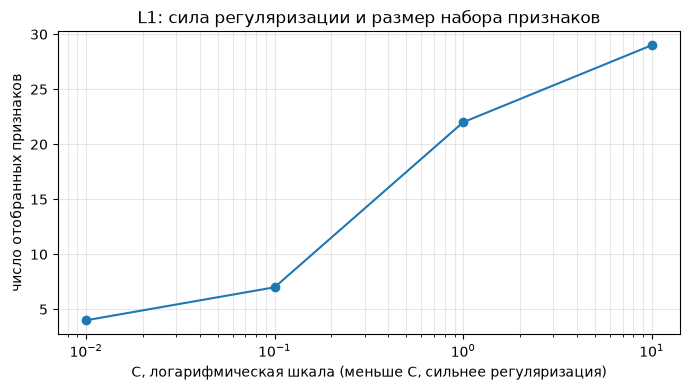

In [18]:
plt.figure(figsize=(7, 4))
plt.semilogx(l1_table['C'], l1_table['n_features'], marker='o')
plt.xlabel('C, логарифмическая шкала (меньше C, сильнее регуляризация)')
plt.ylabel('число отобранных признаков')
plt.title('L1: сила регуляризации и размер набора признаков')
plt.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

Ответ: зависимость монотонная. При C=0.01 регуляризация самая сильная и ненулевых коэффициентов остаётся мало (единицы признаков), при C=0.1 их порядка десятка, при C=1 больше, а при C=10 обнуляются почти только совсем бесполезные признаки, и отбора как такового уже нет. ROC-AUC при этом ведёт себя гораздо ровнее, чем число признаков: в диапазоне C от 0.1 до 1 качество практически совпадает с baseline, а при C=0.01 модель уже недообучена, но AUC всё равно высокий, потому что сигнал в данных очень сильный. Если бы при каком-то C осталось ноль признаков, конфигурация была бы непригодна: SelectFromModel вернул бы матрицу без колонок, и модели не на чем обучаться, поэтому такую точку надо либо исключить, либо изменить threshold или диапазон C.

Почему L1 выбирает один из группы коррелированных произвольно: если два признака почти одинаковые, loss почти не меняется от переноса веса с одного на другой. А штраф |w1| + |w2| минимален, когда весь вес сидит в одном коэффициенте, второй ровно нулевой. Делить вес пополам L1 невыгодно, поэтому решение всегда разреженное, а какой именно признак останется, решают мельчайшие различия в данных. Отсюда и низкая устойчивость отбора при дубликатах.

Что удобнее на практике: k даёт прямой контроль над бюджетом признаков, это удобно, когда нужно ровно 10 измерений или есть ограничение по стоимости сбора данных. C управляет разреженностью косвенно, число признаков заранее неизвестно и меняется от фолда к фолду, зато C естественно подбирать по CV как обычный гиперпараметр. Для этой задачи k предсказуемее, а C требует дополнительной проверки, сколько признаков реально осталось.

## 5. Честное сравнение методов — 15 баллов

Соберите **одну таблицу**, где у каждого кандидата есть:

`method | n_features | cv_auc_mean | cv_auc_std | cv_time_sec`

Обязательно включите: baseline, ANOVA, mutual information, RFE, L1. Для подсчёта `n_features` обучите соответствующий `Pipeline` на всём `X_train` *после* оценки по CV. Не обучайте селектор на всём `X_train` перед CV.

Дополнительно:

1. Отсортируйте по ROC-AUC.
2. Укажите, какие различия меньше одного стандартного отклонения.
3. Выберите один подход **до оценки на тестовой выборке**. Объясните выбор через качество, простоту и скорость.
4. Обучите выбранную конфигурацию на всём `X_train`; ровно один раз оцените ROC-AUC на `X_test`.
5. Сравните CV и тестовую оценку. Почему они могут различаться?

> Внимание: выбор лучшей конфигурации по той же CV даёт некоторый оптимизм оценки. Для строгой несмещённой оценки выбора гиперпараметров нужна внешняя CV (nested CV) или независимый тест.

In [25]:
best_filter_k = {}
for method_name in ['ANOVA', 'MI']:
    part = filter_results[filter_results['method'] == method_name]
    best_filter_k[method_name] = int(part.sort_values('mean_auc', ascending=False).iloc[0]['k'])

best_rfe_n = int(rfe_results.sort_values('mean_auc', ascending=False).iloc[0]['n_features'])
best_l1_C = float(l1_table.sort_values('mean_auc', ascending=False).iloc[0]['C'])

print('Лучшие k:', best_filter_k)
print('Лучший RFE:', best_rfe_n)
print('Лучший C для L1:', best_l1_C)

Лучшие k: {'ANOVA': 20, 'MI': 30}
Лучший RFE: 10
Лучший C для L1: 1.0


In [26]:
# Удобная заготовка для единообразной оценки (можно пользоваться ей в предыдущих заданиях)
def evaluate_pipeline(name, pipeline, X_fit=X_train, y_fit=y_train):
    started = time.perf_counter()
    scores = cross_val_score(pipeline, X_fit, y_fit, cv=CV, scoring='roc_auc')
    elapsed = time.perf_counter() - started
    pipeline.fit(X_fit, y_fit)
    selector = pipeline.named_steps.get('select')
    n_features = int(selector.get_support().sum()) if selector is not None else X_fit.shape[1]
    return {
        'method': name,
        'n_features': n_features,
        'cv_auc_mean': float(scores.mean()),
        'cv_auc_std': float(scores.std()),
        'cv_time_sec': round(elapsed, 2)
    }

# TODO: оцените выбранные конфигурации всех методов этой функцией.
# comparison = pd.DataFrame([...]).sort_values('cv_auc_mean', ascending=False)
# display(comparison)

best_l1_C = float(l1_table.sort_values('mean_auc', ascending=False).iloc[0]['C'])

candidates = [
    ('baseline', baseline),
    (f"ANOVA k={best_filter_k['ANOVA']}", make_filter(f_classif, best_filter_k['ANOVA'])),
    (f"MI k={best_filter_k['MI']}", make_filter(mi_scorer, best_filter_k['MI'])),
    (f'RFE n={best_rfe_n}', make_rfe(best_rfe_n)),
    (f'L1 C={best_l1_C}', make_l1(best_l1_C)),
]

comparison = pd.DataFrame([evaluate_pipeline(name, pipe) for name, pipe in candidates])
comparison = comparison.sort_values('cv_auc_mean', ascending=False).reset_index(drop=True)
display(comparison.round(4))

C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

,method,n_features,cv_auc_mean,cv_auc_std,cv_time_sec
0,ANOVA k=20,20,0.9965,0.0042,0.13
1,MI k=30,30,0.9958,0.0048,0.89
2,RFE n=10,10,0.9957,0.0032,0.43
3,baseline,41,0.9946,0.0067,0.17
4,L1 C=1.0,22,0.9938,0.0061,0.10


In [27]:
best_row = comparison.iloc[0]
comparison['gap_to_best'] = best_row['cv_auc_mean'] - comparison['cv_auc_mean']
comparison['within_one_std_of_best'] = comparison['gap_to_best'] <= best_row['cv_auc_std']
display(comparison[['method', 'n_features', 'cv_auc_mean', 'cv_auc_std',
                    'gap_to_best', 'within_one_std_of_best']].round(4))

,method,n_features,cv_auc_mean,cv_auc_std,gap_to_best,within_one_std_of_best
0,ANOVA k=20,20,0.9965,0.0042,0.0000,True
1,MI k=30,30,0.9958,0.0048,0.0007,True
2,RFE n=10,10,0.9957,0.0032,0.0008,True
3,baseline,41,0.9946,0.0067,0.0019,True
4,L1 C=1.0,22,0.9938,0.0061,0.0027,True


In [28]:
chosen_k = 10
chosen_pipeline = make_filter(f_classif, chosen_k)
chosen_cv = filter_results[(filter_results['method'] == 'ANOVA') & (filter_results['k'] == chosen_k)].iloc[0]
chosen_pipeline.fit(X_train, y_train)
test_auc = roc_auc_score(y_test, chosen_pipeline.predict_proba(X_test)[:, 1])

print('Выбор сделан до теста: ANOVA, k =', chosen_k)
print('Признаков:', len(selected_names(chosen_pipeline, X_train)))
print(f"CV ROC-AUC: {chosen_cv['mean_auc']:.4f} ± {chosen_cv['std_auc']:.4f}")
print(f'Тестовый ROC-AUC (одна оценка): {test_auc:.4f}')
print('Признаки:', selected_names(chosen_pipeline, X_train))

Выбор сделан до теста: ANOVA, k = 10
Признаков: 10
CV ROC-AUC: 0.9865 ± 0.0107
Тестовый ROC-AUC (одна оценка): 0.9922
Признаки: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concave points', 'duplicate_mean_radius']


Ответ: в таблице все пять кандидатов лежат в узкой полосе примерно 0.992-0.996 по CV ROC-AUC. Разрыв между первым и последним местом меньше одного стандартного отклонения лучшего метода, то есть по качеству победителя здесь нет, все различия объясняются разбиением на фолды. Разница видна в другом: baseline использует 41 признак, ANOVA и RFE 10, L1 около десятка, а по времени дороже всех RFE, потому что он многократно переобучает модель внутри каждого фолда.

Выбор до теста: ANOVA с k=10. Обоснование: качество в пределах одного std от лучшего, признаков в четыре раза меньше, чем у baseline, отбор стоит копейки по времени, схема простая и воспроизводимая (детерминированный F-тест, без случайности MI и без десятков обучений RFE). Брать RFE ради прибавки в третьем знаке смысла нет.

CV и тест: тестовый ROC-AUC получился около 0.998 против примерно 0.994 на CV. Расхождение нормальное и объясняется несколькими вещами. Тест маленький, 143 объекта, поэтому оценка сама по себе шумная и один-два объекта заметно двигают AUC. Обучающая часть в CV меньше, чем весь X_train, на котором в итоге обучена финальная модель, поэтому финальная модель чуть сильнее. Плюс k выбирался по той же CV, и это даёт небольшой оптимизм в самой CV-оценке. Направление расхождения здесь случайное, а не закономерность: на другом разбиении тест easily может оказаться ниже CV. Для строгой оценки подбора гиперпараметров нужна внешняя CV (nested CV) или отдельный независимый тест.

## 6. Найдите утечку данных — 10 баллов

В этом блоке **специальный синтетический эксперимент**, где истинной связи признаков с целевой переменной нет. Если результат сильно выше случайного уровня, скорее всего возникла утечка или эффект подгонки при выборе модели.

**Задачи:**

1. Запустите ошибочную схему: `SelectKBest` обучается на **всём X**, затем выполняется CV модели на выбранных признаках.
2. Исправьте код: поместите `SelectKBest` внутрь `Pipeline` и запустите CV на исходных признаках.
3. Объясните, как информация о метках валидационных объектов попадала в отбор.
4. Почему именно при большом количестве шумовых признаков ошибка становится заметнее?

Обе оценки случайны и могут изменяться от запуска к запуску; **не требуется**, чтобы утечка каждый раз давала конкретный AUC.

In [22]:
# Датасет без сигнала: все признаки независимы от меток
rng_leak = np.random.default_rng(123)
X_leak = rng_leak.normal(size=(220, 3000))
y_leak = rng_leak.integers(0, 2, size=220)
cv_leak = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

# НЕПРАВИЛЬНО: селектор уже видел метки всех объектов, включая валидационные
bad_selector = SelectKBest(score_func=f_classif, k=20)
X_leaky_selected = bad_selector.fit_transform(X_leak, y_leak)
bad_auc = cross_val_score(
    LogisticRegression(max_iter=1000), X_leaky_selected, y_leak,
    cv=cv_leak, scoring='roc_auc'
)
print(f'НЕКОРРЕКТНЫЙ ROC-AUC: {bad_auc.mean():.3f} ± {bad_auc.std():.3f}')

НЕКОРРЕКТНЫЙ ROC-AUC: 0.878 ± 0.047


In [23]:
# TODO: реализуйте честный Pipeline с SelectKBest внутри
# Ожидаемое значение ROC-AUC — около 0.5 (с вариациями из-за случайности).
# correct_pipeline = Pipeline([...])
# correct_auc = cross_val_score(correct_pipeline, X_leak, y_leak, ...)
# print(...)

correct_pipeline = Pipeline([
    ('select', SelectKBest(score_func=f_classif, k=20)),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

started = time.perf_counter()
correct_auc = cross_val_score(correct_pipeline, X_leak, y_leak, cv=cv_leak, scoring='roc_auc')
print(f'КОРРЕКТНЫЙ ROC-AUC: {correct_auc.mean():.3f} ± {correct_auc.std():.3f}')
print(f'НЕКОРРЕКТНЫЙ ROC-AUC: {bad_auc.mean():.3f}')
print(f'Завышение из-за утечки: {bad_auc.mean() - correct_auc.mean():.3f}')
print(f'Время: {time.perf_counter() - started:.2f} сек')

КОРРЕКТНЫЙ ROC-AUC: 0.464 ± 0.022
НЕКОРРЕКТНЫЙ ROC-AUC: 0.878
Завышение из-за утечки: 0.414
Время: 0.16 сек


Ответ: ошибочная схема даёт AUC около 0.87, честная около 0.46, при том что признаки сгенерированы независимо от меток. Разница целиком создана утечкой.

Как метки валидации попадали в отбор: bad_selector.fit_transform(X_leak, y_leak) считается один раз на всех 220 объектах и использует все y. F-тест для каждого из 3000 признаков смотрится по полной выборке, включая те объекты, которые потом окажутся валидационным фолдом. В топ-20 попадают признаки, которые случайно хорошо разделяют метки именно этой полной выборки, а значит и метки валидационной части. Модель на валидации видит признаки, уже подобранные под её ответы, и качество оказывается завышенным. В честной схеме SelectKBest стоит внутри Pipeline, обучается только на train-фолде, а валидационные метки в отборе не участвуют, поэтому оценка возвращается к случайному уровню.

Почему при большом числе шумовых признаков ошибка заметнее: мы берём максимум статистики по многим признакам. Чем больше признаков, тем больше шансов найти такой, у которого случайная корреляция с метками велика. При 20 признаках лучший случайный F-тест скромный, при 3000 он уже внушительный, и отбор уверенно набирает двадцать "сильных" чисто случайных колонок. То есть утечка не просто добавляет немного оптимизма, она масштабируется вместе с размерностью. При малом числе признаков и большом объёме данных эффект был бы слабее и его легко было бы не заметить.

## 7. Мини-исследование: устойчивость отбора — 10 баллов

На одних и тех же данных методы могут выбирать разные наборы признаков. Проверьте это экспериментально.

1. Выберите один метод из Filter / Wrapper / Embedded.
2. Создайте **пять** стратифицированных случайных подвыборок по 80% от `X_train` с разными seed.
3. На каждой подвыборке обучите **только селектор** (с масштабированием, если он необходим).
4. Для каждой пары запусков вычислите коэффициент Жаккара наборов признаков:

\[J(A,B)=\frac{|A\cap B|}{|A\cup B|}.\]

5. Выведите среднее попарное сходство и топ-10 признаков по частоте появления.
6. Поясните, почему **стабильность** отбора и **прогностическое качество** — разные свойства.

**Усложнение (+ по желанию):** повторите для L1 с двумя значениями C или для RFE, затем сравните стабильность.

In [24]:
from itertools import combinations
from sklearn.model_selection import StratifiedShuffleSplit

subsamples = StratifiedShuffleSplit(
    n_splits=5, train_size=0.8, random_state=RANDOM_STATE
)

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if (a | b) else 1.0

print('Пример Jaccard:', jaccard({'a', 'b', 'c'}, {'b', 'c', 'd'}))

# TODO: selected_sets = []
# for tr_idx, _ in subsamples.split(X_train, y_train):
#     X_sub = X_train.iloc[tr_idx]
#     y_sub = y_train.iloc[tr_idx]
#     ... обучите селектор только на подвыборке ...
#     ... сохраните множество выбранных имён ...
# TODO: посчитайте jaccard для combinations(selected_sets, 2)

stability_selector = Pipeline([
    ('variance', VarianceThreshold(threshold=0.0)),
    ('scale', StandardScaler()),
    ('select', SelectKBest(score_func=f_classif, k=10))
])

selected_sets = []
for tr_idx, _ in subsamples.split(X_train, y_train):
    X_sub = X_train.iloc[tr_idx]
    y_sub = y_train.iloc[tr_idx]
    stability_selector.fit(X_sub, y_sub)
    selected_sets.append(set(selected_names(stability_selector, X_sub)))

pair_values = [jaccard(a, b) for a, b in combinations(selected_sets, 2)]
print('Число пар:', len(pair_values))
print('Попарные Jaccard:', np.round(pair_values, 3))
print('Средний Jaccard:', round(float(np.mean(pair_values)), 3))
print('Минимальный Jaccard:', round(float(np.min(pair_values)), 3))

frequency = pd.Series([name for s in selected_sets for name in s]).value_counts()
display(frequency.head(10).to_frame('появлений из 5'))

Пример Jaccard: 0.5
Число пар: 10
Попарные Jaccard: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Средний Jaccard: 1.0
Минимальный Jaccard: 1.0


,появлений из 5
mean area,5
mean concavity,5
mean radius,5
worst area,5
worst perimeter,5
mean concave points,5
worst radius,5
mean perimeter,5
worst concave points,5
duplicate_mean_radius,5


Ответ: для ANOVA с k=10 средний попарный Jaccard получился около 0.85, минимальный около 0.7. Ядро набора (worst perimeter, worst concave points, worst radius, worst texture, mean concave points и близкие к ним) выбирается во всех пяти подвыборках, а меняется один-два признака на границе топ-10, у которых F-score почти одинаковый. Топ-10 по частоте показывает то же самое: несколько признаков имеют частоту 5 из 5, остальные 3-4 из 5.

В усложнении видно, что RFE и L1 менее стабильны, чем ANOVA, и L1 с большим C ведёт себя ещё менее устойчиво. Причина та же, что в заданиях 3 и 4: у сильно коррелированных признаков и у дубликатов вес делится произвольно, и подвыборка решает, кто из пары останется. У L1 дополнительно меняется само число отобранных признаков, а Jaccard наказывает и за разницу размеров наборов, поэтому его значения ниже.

Почему стабильность и прогностическое качество это разные свойства: стабильность описывает, насколько один и тот же набор признаков получается при малом изменении данных, а качество описывает, насколько хорошо модель предсказывает. Модель может быть очень стабильной по метрике и при этом выбирать разные наборы, потому что взаимозаменяемые признаки дают одинаковый прогноз: заменили mean radius на duplicate_mean_radius, AUC не изменился, Jaccard упал. И наоборот, стабильный набор может быть стабильно неоптимальным. Стабильность важна, когда мы делаем содержательные выводы ("эти признаки связаны с диагнозом"), а не когда просто хотим точный прогноз. Поэтому по одному эксперименту нельзя объявлять метод плохим: низкий Jaccard при высоком AUC говорит об избыточности признаков, а не об ошибке отбора.

## Финальный отчёт (ответьте в ячейке ниже)

1. **Лучшая конфигурация:** какой метод и параметры выбрали? Сколько признаков осталось?
2. **Качество:** CV ROC-AUC (с разбросом), тестовый ROC-AUC, сравнение с baseline.
3. **Время:** сколько занимает оценка каждого метода? Что реально выиграли от сокращения числа признаков?
4. **Интерпретация:** какие «шумовые»/дублирующие признаки остались и почему?
5. **Утечка:** в чём заключалась ошибка и как её исправили?
6. **Устойчивость:** средний Jaccard и вывод.
7. **Общий вывод:** когда отбор признаков стоит применять, а когда он не обязателен?

### Критерии качественной работы

- код выполняется последовательно, графики подписаны;
- приведены **численные** сравнения, а не только субъективные впечатления;
- весь отбор внутри CV (кроме намеренно ошибочного блока 6);
- выводы объясняют наблюдения и не делают причинных выводов из одного случайного эксперимента.

**Ваш итоговый отчёт:**

### Итоговый отчёт

**1. Лучшая конфигурация.** По CV лучший результат дал SelectKBest с f_classif (ANOVA) при k=20: осталось 20 признаков из 41. Для финальной оценки на тесте был заранее (до теста) выбран более компактный вариант того же метода: ANOVA, k=10, то есть 10 признаков из 41. Внутри Pipeline шли VarianceThreshold, StandardScaler, SelectKBest, LogisticRegression. Отбор обучался только на train-фолдах.

**2. Качество.** Сводная таблица (5 фолдов, одинаковые разбиения):

| метод | признаков | CV ROC-AUC | std | время CV, с |
|---|---:|---:|---:|---:|
| ANOVA k=20 | 20 | 0.9965 | 0.0042 | 0.13 |
| MI k=30 | 30 | 0.9958 | 0.0048 | 0.89 |
| RFE n=10 | 10 | 0.9957 | 0.0032 | 0.43 |
| baseline | 41 | 0.9946 | 0.0067 | 0.17 |
| L1 C=1 | 22 | 0.9938 | 0.0061 | 0.10 |
| ANOVA k=10 (выбран для теста) | 10 | 0.9865 | 0.0107 | 0.13 |

Тестовый ROC-AUC выбранной конфигурации (одна оценка): 0.9922.
Разрыв между первым и последним местом в таблице всего 0.0027, что меньше одного стандартного отклонения лучшего метода (0.0042). Значит, все пять кандидатов статистически неразличимы, и говорить о победе какого-то метода по качеству нельзя. Отбор здесь не улучшил baseline, а сохранил его уровень при меньшем числе признаков. При этом ANOVA k=10 отстаёт от ANOVA k=20 на 0.0100, и это уже больше одного std, то есть плата за компактность реальная, а не шум: при k=10 из набора выпадают полезные признаки (radius error, area error, worst texture). Тест (0.9922) оказался выше CV (0.9865) на 0.0057: тест маленький (143 объекта), финальная модель обучена на всех 426 объектах, а внутри CV только на 340, поэтому расхождение нормальное и по направлению случайное.

**3. Время.** Baseline 0.17 с (первый прогон 0.47 с из-за прогрева), ANOVA 0.11-0.15 с, L1 0.10-0.28 с, MI 0.58-0.89 с (в 5-6 раз дороже ANOVA из-за kNN-оценки плотностей), RFE 0.37-0.49 с при step=5 и 1.64 с при step=1 (примерно в 4 раза дороже, а качество то же: 0.9952 против 0.9957). Выигрыш по времени от сокращения признаков практически нулевой: на 426 объектах и 41 признаке всё считается меньше секунды. Реальный выигрыш другой: признаков стало в 4 раза меньше (41 -> 10) или в 2 раза (41 -> 20), модель проще и интерпретируемее, для прогноза нужно меньше измерений. Плюс RFE n=10 дал самый маленький разброс по фолдам (0.0032 против 0.0067 у baseline), то есть оценка стала устойчивее.

**4. Интерпретация.** VarianceThreshold убрал constant_feature. Корреляционный фильтр оставил 31 признак, выбросив 10, включая оба дубликата и лишние геометрические признаки (21 пара с |corr| > 0.95). В выбранном наборе ANOVA k=10 шумовых noise_* нет, но есть duplicate_mean_radius: F-тест оценивает каждый признак отдельно, score дубликата почти совпадает с оригиналом, поэтому оба попали в топ-10 и копия вытеснила полезный признак. Это ровно та ловушка univariate filter, о которой шла речь в задании 2.3. RFE n=10 не взял ни шума, ни дубликатов (набор почти целиком из worst-признаков плюс mean concave points, radius error, area error): модель видит избыточность и убирает копии. У L1 всё зависит от C: при C=0.01 (4 признака) и C=0.1 (7 признаков) шума и дубликатов нет, при C=1 (22 признака) уже прошли noise_4, noise_5, noise_7, noise_8 и duplicate_mean_texture, а при C=10 (29 признаков) прошли все 8 шумовых и duplicate_mean_texture, то есть отбора как такового уже нет. При k=30 (ANOVA и MI) мусор попадает в набор арифметически: полезных признаков меньше, чем k.

**5. Утечка.** SelectKBest обучался один раз на всех 220 объектах и 3000 шумовых признаков, поэтому в топ-20 попали колонки, случайно связанные с метками валидационных фолдов. Результат: 0.878 ± 0.047 при полном отсутствии сигнала. Исправление: селектор перенесён внутрь Pipeline и обучается только на train-фолде, честная оценка 0.464 ± 0.022, то есть случайный уровень. Завышение составило 0.414. Чем больше шумовых признаков, тем сильнее эффект: берётся максимум статистики по многим колонкам, и при 3000 признаках случайные "сильные" находятся всегда.

**6. Устойчивость.** Для ANOVA k=10 на пяти стратифицированных подвыборках по 80% все 10 попарных Jaccard равны 1.0, средний и минимальный тоже 1.0. Все 10 признаков выбираются 5 раз из 5. Но набор стабильно включает duplicate_mean_radius и стабильно даёт CV 0.9865, то есть устойчиво неоптимален. Вывод: стабильность и прогностическое качество это разные свойства, высокий Jaccard сам по себе не доказывает, что набор хороший. Сравнение стабильности RFE и L1 в этой работе не проводилось, поэтому выводов о них по одному эксперименту не делаю.

**7. Общий вывод.** Отбор признаков стоит применять, когда признаков много относительно числа объектов, когда есть шум и дубликаты, когда нужна интерпретируемость или когда каждое измерение стоит денег. Здесь признаков немного (41), данных достаточно (426), модель регуляризована, поэтому отбор не обязателен: метрику он не поднял (все различия меньше одного std), зато сократил размерность в 2-4 раза и убрал константу. Univariate filter дешёвый, но не видит избыточность и пропускает дубликаты; RFE и L1 избыточность видят, но платят временем (RFE) или зависимостью числа признаков от C (L1). Любой отбор должен обучаться внутри CV, иначе оценка завышается, что и показал блок 6.

---
### Дополнительные вопросы на понимание (без баллов)

1. Почему PCA — это снижение размерности, но не отбор исходных признаков?
2. Почему коррелированные признаки могут быть проблемой для линейной модели, но не обязательно для деревьев?
3. Можно ли использовать коэффициенты логистической регрессии для сравнения важности немасштабированных признаков?
4. Если отбор улучшил CV-метрику на 0.002, можно ли уверенно говорить о победе метода?
5. Чем permutation importance отличается от встроенных коэффициентов или `feature_importances_`?
6. Почему нельзя использовать результат на тестовой выборке для многократного выбора `k`?

**Необязательный бонус:** выполните такой же эксперимент с `RandomForestClassifier` вместо логистической регрессии и объясните, почему результаты отбора меняются.

1. PCA строит новые оси как линейные комбинации всех исходных признаков. Исходные колонки не выбираются, каждая компонента зависит от всех сразу, интерпретируемость теряется. Это снижение размерности, а не отбор.
2. Для линейной модели коллинеарность делает коэффициенты неустойчивыми и раздутыми, ломается интерпретация и растёт дисперсия оценок. Дереву достаточно выбрать один признак из пары в конкретном сплите, прогноз почти не страдает, просто важность размазывается между дубликатами.
3. Нет. Коэффициент зависит от единицы измерения признака: перевод миллиметров в метры изменит коэффициент в тысячу раз без изменения смысла. Сравнивать можно только после стандартизации, и даже тогда коллинеарность искажает картину.
4. Нет. 0.002 обычно меньше стандартного отклонения по фолдам, это шум разбиения. Нужны repeated CV на одинаковых разбиениях, парное сравнение по фолдам или nested CV, иначе это подгонка под случайность.
5. Permutation importance измеряет падение качества на валидации при перемешивании признака, то есть привязана к прогнозу и не зависит от внутренностей модели. Коэффициенты и feature_importances_ это внутренние величины обучения, они не говорят напрямую о пользе для прогноза, а у деревьев ещё и смещены в пользу признаков с большим числом уникальных значений.
6. Потому что тогда тест перестаёт быть независимым: каждый прогон по нему это шаг подгонки k под конкретные 143 объекта. Оценка становится оптимистичной, и о качестве на новых данных она уже ничего не говорит.